# **Introduction**

<div style = "text-align: justify;">

***Naive Bayes** is a machine learning classification algorithm based on the Bayes' Theorem that predicts a data point's category based on probability*. It assumes that each feature contributes to the result independently, even if this isn’t always true in reality (this is called the “naive” assumption). Naive Bayes excels in a variety of real-world applications, including spam filtering, document categorization, and sentiment analysis. There are **three** types of naive Bayes classifiers, each suited for different types of data:

1. Multinomial Naive Bayes
2. Bernoulli Naive Bayes
3. Gaussian Naive Bayes

***Neural Network** is a machine learning model inspired by the human brain that learns patterns by passing data through layers of interconnected nodes (called neurons)*. Each neuron applies a weight and an activation function to the input, allowing the network to model complex, non-linear relationships between inputs and outputs. By adjusting these weights during training, neural networks can learn from data and improve their predictions over time. They are widely used in tasks such as image recognition, speech processing, recommendation systems, and natural language processing. There are various types of neural networks, some of them are not appropriate for the type of dataset in this project.

> *This project is aimed at comparing the Naive Bayes Classifiers mentioned above with Neural Network Models and see how much the performance changes. This project is a continuation of [this project](https://github.com/tasnimtalha09/applied-machine-learning-for-business/tree/main/Project%2001%20—%20Understanding%20%26%20Explaining%20a%20Machine%20Learning%20Algorithm), where we saw that **Multinomial Naive Bayes** outperforms the other two naive Bayes classifiers on text data. So, we will compare the performance of Multinomial Naive Bayes with Neural Network Models in this project.*

## The Models Used

The models used in this project are:
1. Multinomial Naive Bayes
2. Multi-Layer Perceptron (MLP)
3. 1D Convolutional Neural Network (1D CNN)
4. Gated Recurrent Unit (GRU)
5. Long Short-Term Memory (LSTM)
6. Bidirectional Long Short-Term Memory (BiLSTM)
7. CNN + LSTM Hybrid Model

A short introduction on each model along with relevant links are provided in the respective sections.

</div>

<div style = "text-align: justify;">

## Aims & Objectives

### **Aim**
To investigate the effectiveness of neural network approaches for SMS spam detection.

### **Broad Objective**
To compare the performance of Multinomial Naive Bayes with various Neural Network Models on the SMS Spam Collection Dataset for spam detection and see whether neural networks outperform the Naive Bayes classifier on this text classification task.

### **Specific Objectives**

1. To preprocess and prepare the SMS Spam Collection dataset for classification by encoding target labels, tokenizing text data using CountVectorizer, TfidfVectorizer, and Keras Tokenizer, and splitting the data into training and testing sets while preserving the class distribution through stratified sampling.
2. To implement and train **seven** classification models—Multinomial Naive Bayes (MNB), Multi-Layer Perceptron (MLP), 1D Convolutional Neural Network (1D CNN), Gated Recurrent Unit (GRU), Long Short-Term Memory (LSTM), Bidirectional LSTM (BiLSTM), and CNN + LSTM Hybrid—on the SMS spam detection task.
3. To evaluate and compare model performance using multiple metrics including accuracy, precision, recall, F1-score, ROC-AUC score, and confusion matrices to determine which model best balances spam detection effectiveness with minimal false positives and false negatives.
4. To assess model generalization capability by analyzing the difference between training and testing accuracies to identify potential overfitting issues and ensure reliable performance on unseen data.
5. To determine whether complex neural network architectures provide significant performance gains over the simpler probabilistic Multinomial Naive Bayes classifier for text-based spam detection, thereby informing model selection decisions based on the trade-off between complexity and accuracy.

</div>

## Setting Up the Environment

<div style = "text-align: justify;">

After running the whole notebook multiple times, we saw that the results vary each time due to the inherent randomness in neural network training (e.g., weight initialization, data shuffling). To ensure consistent and reproducible results across different runs, we set random seeds for all relevant libraries. This way, the random processes produce the same outcomes each time the code is executed.

</div>

In [1]:
# importing the library needed to set the environment variables
import os

# setting the environment variables before importing TensorFlow, because TensorFlow reads them only once, when it is first loaded. here, 0 = show everything, 1 = hide info, 2 = hide info & warnings, 3 = hide info, warnings & errors
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# forcing TensorFlow to use operations that give the same result every run
os.environ["TF_DETERMINISTIC_OPS"] = "1"

# standard library
import random

# data manipulation
import numpy as np
import pandas as pd

# data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# data loading (only used when the local file is missing)
import io
import zipfile
import requests

# model selection
from sklearn.model_selection import train_test_split

# text preprocessing (for Multinomial Naive Bayes and the MLP) & pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline

# classical machine learning model
from sklearn.naive_bayes import MultinomialNB

# model evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

# deep learning: text preprocessing (for the CNN, GRU, LSTM, BiLSTM, and hybrid models)
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# deep learning: model building
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    BatchNormalization,
    Embedding,
    Conv1D,
    MaxPooling1D,
    GlobalMaxPooling1D,
    Input,
    GRU,
    LSTM,
    Bidirectional
)

# deep learning: training
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import set_random_seed

# setting the random seeds AFTER importing the libraries, because the seed functions belong to the libraries
SEED = 49
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

## Dataset Overview

<div style = "text-align: justify;">

The dataset used is the **SMS Spam Collection** dataset, which is a set of **5,572** SMS tagged messages that have been collected for mobile phone spam research. The dataset is available [here](https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip) to download and work manually or [here](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) if directly fetched from online. Both versions of the code are tied with a `try-except` block. If the local file is not found, it will fetch from online.

</div>

In [2]:
# trying to load the local file first
try:
    sms = pd.read_csv(
        filepath_or_buffer = "../datasets/SMSSpamCollection",
        sep = "\t",
        header = None,
        names = ["label", "message"]
    )
    print("File loaded successfully from local storage.")

# downloading and loading the dataset from the web if the file is not found
except FileNotFoundError:
    print("Local file not found. Fetching it online...")

    # downloading the zip file from UCI repository
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"
    r = requests.get(url)

    # extracting and reading the data file inside the zip
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        with z.open("SMSSpamCollection") as f:
            sms = pd.read_csv(
                filepath_or_buffer = f,
                sep = "\t",
                header = None,
                names = ["label", "message"]
            )

    print("File successfully fetched online and loaded.")

# displaying the first few rows
sms.head(n = 10)

File loaded successfully from local storage.


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


<div style = "text-align: justify;">

We can see that the dataset has two columns: `label` and `message`. The `label` column contains the target variable, which indicates whether the message is spam or ham (not spam). The `message` column contains the actual text of the SMS message.

We quickly check the proportion of hams and spams to check the overall balance. This will later help us in the train-test split.

</div>

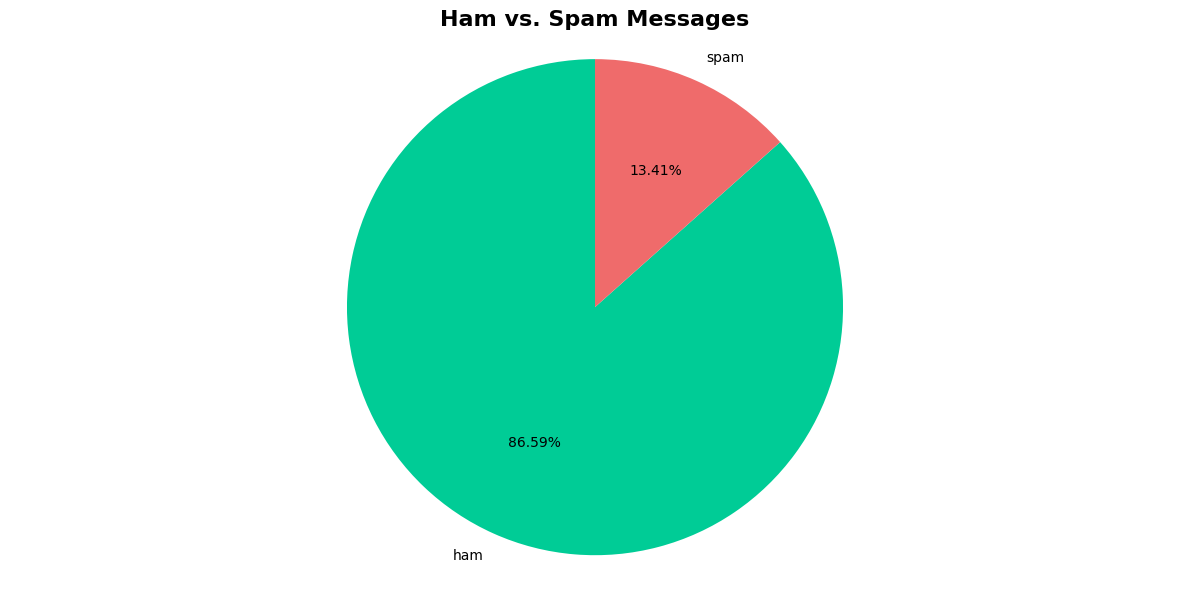

In [3]:
# calculating the ratio of hams and spams
spam_ham_ratio = round(number = sms["label"].value_counts(normalize = True), ndigits = 4) * 100

# creating a simple pie chart
plt.figure(figsize = (12, 6))
plt.pie(
    x = spam_ham_ratio.values,
    labels = spam_ham_ratio.index,
    autopct = "%1.2f%%",
    colors = ["#00CC96", "#EF6B6B"],
    startangle = 90
)

# adding title and formatting the chart
plt.title(label = "Ham vs. Spam Messages", fontsize = 16, fontweight = "bold")
plt.axis("equal")
plt.tight_layout()
plt.show()

<div style = "text-align: justify;">

So, this dataset has roughly **87%** ham messages and **13%** spam messages. The dataset is imbalanced, which means that the number of instances in each class is not equal. This can lead to biased results if not handled properly. We will preserve this spam:ham ratio while splitting the dataset.

</div>

# **Machine Learning**

Now, we preprocess the data and train the models one by one. The detailed explanation of each step is provided in the notebook itself.

## Data Preprocessing

### **Target Variable Encoding**

We encode the labels, where `ham` is encoded as 0 and `spam` is encoded as 1.

In [4]:
# encoding the target variable
sms["label_encoding"] = sms["label"].map({"ham": 0, "spam": 1})

### **Train-Test Split**

<div style = "text-align: justify;">

Now, time for the data split. We split the data into **three** sets, each with a different job:

* **Training set (64%):** the data the models learn from.
* **Validation set (16%):** the data used to make decisions during development, such as when the neural networks should stop training (early stopping) and, later, which model performs best.
* **Test set (20%):** the data kept untouched for the final evaluation of the models.

We do this in two steps. First, we set aside **20%** of the data as the test set. Then we split the remaining **80%** into training (**64%** of it) and validation (**16%** of it). Using a separate validation set means the test set is not involved in any decision, so the final test results are a fair estimate of how the models will perform on unseen messages. It also lets every model, including Multinomial Naive Bayes, train on exactly the same data, which keeps the comparison fair.

Both splits use stratified sampling, so the proportion of ham and spam messages (about 87:13) is preserved in all three sets. Without it, a random split could leave one set with noticeably fewer spam messages, which would make the scores less reliable, especially for the smaller validation set.

</div>

In [5]:
# splitting off the test set first (20%), stratified to preserve the ham:spam ratio
X_train_full, X_test, y_train_full, y_test = train_test_split(
    sms["message"],
    sms["label_encoding"],
    test_size = 0.2,
    stratify = sms["label_encoding"],
    random_state = SEED
)

# splitting the remaining data into a training set (80%) and a validation set (20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size = 0.2,
    stratify = y_train_full,
    random_state = SEED
)

# checking the sizes and the spam share of every set
for name, labels in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:<15}: {len(labels):,} messages, {labels.mean():.2%} spam")

Train          : 3,565 messages, 13.41% spam
Validation     : 892 messages, 13.45% spam
Test           : 1,115 messages, 13.36% spam


Now that the data is preprocessed, we can move on to model training and evaluation.

## Modeling

### **1. Multinomial Naive Bayes**

<div style = "text-align: justify;">

Multinomial Naive Bayes is a version of the Naive Bayes algorithm that is best suited for discrete data and is commonly used in text classification issues like spam detection or sentiment analysis. Instead of just checking whether a word appears or not (which is the working mechanism of Bernoulli Naive Bayes), it looks at how many times each word repeats in a document and uses those counts to calculate probabilities for each class.

First, we encode the data for MultinomialNB. We encode the data using `CountVectorizer` for Multinomial Naive Bayes. This encoder converts a collection of text documents to a matrix of token counts, i.e., it counts how many times each word appears. We also used `stop_words = "english"` in both vectorizers to remove common English words that may not be useful for classification. Examples of such stop words include "the", "is", "in", "and", etc. Removing these words can help improve the performance of the model by reducing noise in the data.

Instead of vectorizing the text separately before passing it to each model, we combine each vectorizer and classifier into a scikit-learn `Pipeline`. We define the three pipelines once and reuse them for training, prediction, ROC curve analysis, overfitting checks, and cross-validation. More importantly, pipelines prevent preprocessing leakage during cross-validation. Each pipeline learns its vocabulary and, where applicable, IDF weights only from the data used to fit it. For the final model, this means using only the training set. During cross-validation, the vectorizer is fitted separately on the training portion of each fold. Without pipelines, vectorizing the entire training set before cross-validation would allow the validation folds to influence the vocabulary and IDF weights, resulting in **preprocessing leakage**.

</div>

In [6]:
# creating a pipeline to bundle the vectoriser and the classifier together
mnb_pipeline = Pipeline(
    steps = [
        ("vectoriser", CountVectorizer(stop_words = "english")),
        ("classifier", MultinomialNB())
    ]
)

# fitting the pipeline on the raw training text
mnb_pipeline.fit(X = X_train, y = y_train)

# predicting the test dataset
y_predict_test_mnb = mnb_pipeline.predict(X = X_test)

<div style = "text-align: justify;">

After fitting the model, we make predictions on the test set using the **evaluation metrics**, **confusion matrix**, and **classification report** (which provide detailed metrics such as precision, recall, and F1-score) to evaluate the model's performance.

</div>

In [7]:
# calculating the evaluation metrics for the test dataset (spam = class 1)
accuracy_test_mnb = accuracy_score(y_true = y_test, y_pred = y_predict_test_mnb)
precision_test_mnb = precision_score(y_true = y_test, y_pred = y_predict_test_mnb)
recall_test_mnb = recall_score(y_true = y_test, y_pred = y_predict_test_mnb)
f1_test_mnb = f1_score(y_true = y_test, y_pred = y_predict_test_mnb)

# generating the classification report for the test dataset
report_mnb = classification_report(
    y_true = y_test,
    y_pred = y_predict_test_mnb,
    target_names = ["ham", "spam"]
)

# printing a summary report
print(
f"""Model Performance Report for Multinomial Naive Bayes

Spam F1-Score: {f1_test_mnb:.3%}
Accuracy Score: {accuracy_test_mnb:.3%}

{report_mnb}"""
)

Model Performance Report for Multinomial Naive Bayes

Spam F1-Score: 95.563%
Accuracy Score: 98.834%

              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       966
        spam       0.97      0.94      0.96       149

    accuracy                           0.99      1115
   macro avg       0.98      0.97      0.97      1115
weighted avg       0.99      0.99      0.99      1115



<div style = "text-align: justify;">

**Key Insights**
* The model achieves an overall accuracy of **98.83%**, indicating strong classification performance.  
* For spam messages, it records a **precision of 97%**, meaning most predicted spam messages are actually spam.  
* The **recall of 94%** shows that a small portion of spam messages are missed.  
* This results in an **F1-score of 95.56%**, reflecting a strong balance between precision and recall.
* **Overall**, Multinomial Naive Bayes performs exceptionally well on spam detection.

> *From the next model, we will skip the key insights section to avoid redundancy. After running all the models, we will summarize the performance metrics in a comparative table and generate an overall key insights section.*

Now, we generate the confusion matrix for Multinomial Naive Bayes.

</div>

In [8]:
# calculating the confusion matrix
matrix_mnb = confusion_matrix(y_true = y_test, y_pred = y_predict_test_mnb)

<div style = "text-align: justify;">

> *Similar to the performance metrics, we will combine all the confusion matrices from the different models into a single comparative visualization and generate insights from there.*

Finally, we generate the ROC (Receiver Operating Characteristic) AUC (Area Under the Curve) score. We will plot all the ROC curves for the models in a single figure later.

</div>

In [9]:
# calculating the MultinomialNB probabilities
y_prob_mnb = mnb_pipeline.predict_proba(X = X_test)[:, 1]
fpr_mnb, tpr_mnb, thresholds_mnb = roc_curve(y_true = y_test, y_score = y_prob_mnb)

# Calculating the ROC-AUC for the model
roc_score_mnb = roc_auc_score(y_true = y_test, y_score = y_prob_mnb)
print(f"The ROC-AUC score for Multinomial Naive Bayes is: {roc_score_mnb:.3%}")

The ROC-AUC score for Multinomial Naive Bayes is: 99.250%


<div style = "text-align: justify;">

> *Similar to the performance metrics and confusion matrices, we will combine all the ROC AUC curves from the different models into a single comparative visualization and generate insights from there.*

Now, we will proceed to fit the Neural Network models. We will cover a total of **six** different models:
1. Multi-Layer Perceptron (MLP)
2. 1D Convolutional Neural Network (1D CNN)
3. Gated Recurrent Unit (GRU)
4. Long Short-Term Memory (LSTM)
5. Bidirectional Long Short-Term Memory (BiLSTM)
6. CNN + LSTM Hybrid Model

Since training settings are shared by all neural networks, so that differences come from the architecture and not from the training setup. For that reason, we will set the training settings first and then proceed to fit the models one by one.

</div>

In [10]:
# setting the training settings
MAX_EPOCHS = 50
PATIENCE = 10
BATCH_SIZE = 32

### **2. Multi-Layer Perceptron**

<div style = "text-align: justify;">

*A **Multi-Layer Perceptron (MLP)** is a basic type of artificial neural network made of an input layer, one or more hidden layers, and an output layer of interconnected “neurons” that transform and learn patterns in data using nonlinear activations*. Its goal is to model complex relationships between inputs and outputs by adjusting weights during training. MLPs are used for **supervised tasks** like classification or regression, such as recognizing handwritten digits from image pixels or predicting whether an email is spam based on features.

The Multi-Layer Perceptron uses `TfidfVectorizer`, which converts each message into **TF-IDF** features (*Term Frequency-Inverse Document Frequency*): a score of how important each word is to a message relative to the whole training corpus. We use `stop_words = "english"` here as well.

Unlike Multinomial Naive Bayes, the vectoriser cannot be bundled into a `Pipeline` with a Keras model, so we are careful by hand: the vectoriser is **fitted on the training set only**, and then used to transform the validation and test sets. The sparse output is converted to a dense `float32` array with `.toarray()`, which is the format the Keras `Dense` layer expects.

</div>

In [11]:
# creating the TF-IDF vectoriser
vectoriser_mlp = TfidfVectorizer(stop_words = "english")

# learning the vocabulary from the training set only, then transforming all three sets
X_train_mlp = vectoriser_mlp.fit_transform(raw_documents = X_train).toarray().astype("float32")
X_val_mlp = vectoriser_mlp.transform(raw_documents = X_val).toarray().astype("float32")
X_test_mlp = vectoriser_mlp.transform(raw_documents = X_test).toarray().astype("float32")

# printing the training matrix
print(f"Training matrix: {X_train_mlp.shape[0]:,} messages x {X_train_mlp.shape[1]:,} features")

Training matrix: 3,565 messages x 6,644 features


Now, we proceed to fit the model.

In [12]:
# re-seeding right before building, so this model gives the same result whether it runs alone or after other cells
set_random_seed(SEED)

# building the MLP for binary classification
mlp = Sequential(
    [
        # input layer
        Input(shape = (X_train_mlp.shape[1],)),

        # hidden layer 01
        Dense(units = 256, activation = "relu"),
        BatchNormalization(),
        Dropout(rate = 0.3),

        # hidden layer 02
        Dense(units = 128, activation = "relu"),
        BatchNormalization(),
        Dropout(rate = 0.3),

        # hidden layer 03
        Dense(units = 64, activation = "relu"),
        BatchNormalization(),
        Dropout(rate = 0.2),

        # hidden layer 04
        Dense(units = 32, activation = "relu"),

        # output layer (sigmoid outputs the probability of spam)
        Dense(units = 1, activation = "sigmoid")
    ]
)

# compiling the model
mlp.compile(
    optimizer = Adam(learning_rate = 0.001),
    loss = "binary_crossentropy",
    metrics=["accuracy"]
)

# stopping when the validation loss stops improving, and keeping the weights from the best epoch
early_stopping_mlp = EarlyStopping(
    monitor = "val_loss",
    patience = PATIENCE,
    restore_best_weights = True
)

# fitting the model on the training set, monitoring the separate validation set
history_mlp = mlp.fit(
    x = X_train_mlp,
    y = y_train,
    validation_data = (X_val_mlp, y_val),
    epochs = MAX_EPOCHS,
    batch_size = BATCH_SIZE,
    callbacks = [early_stopping_mlp],
    verbose = 0
)

# printing the model summary
mlp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     1,701,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,236,741 (19.98 MB)

 Trainable params: 1,745,281 (6.66 MB)

 Non-trainable params: 896 (3.50 KB)

 Optimizer params: 3,490,564 (13.32 MB)

<div style = "text-align: justify;">

After each neural network is trained, we plot its training and validation loss for every epoch. The validation loss is the honest one: when it stops falling and starts rising while the training loss keeps falling, the model has begun to memorise the training set. Early stopping then restores the weights from the best epoch (the dashed line).

</div>

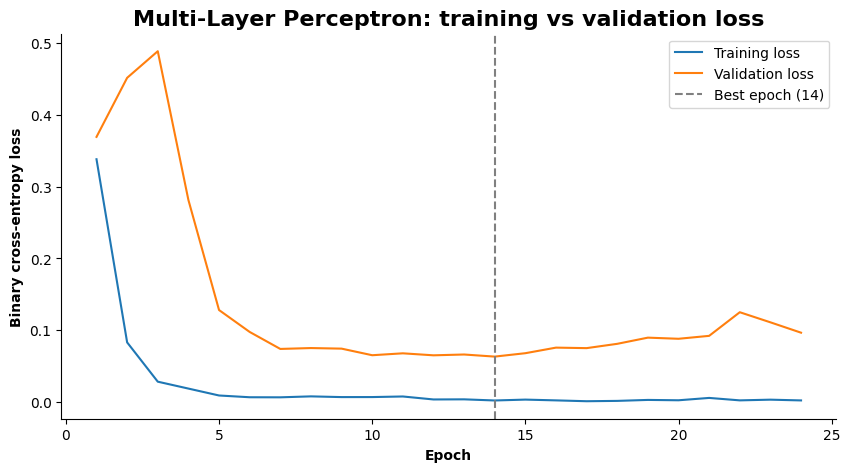

Multi-Layer Perceptron trained for 24 epochs; weights restored from epoch 14


In [13]:
# creating a function that will plot the training and validation loss, and mark the epoch whose weights were kept
def plot_training_history(history, model_name):
    epochs = range(1, len(history.history["loss"]) + 1)
    best_epoch = int(np.argmin(history.history["val_loss"])) + 1

    plt.figure(figsize = (10, 5))
    plt.plot(epochs, history.history["loss"], label = "Training loss")
    plt.plot(epochs, history.history["val_loss"], label = "Validation loss")
    plt.axvline(x = best_epoch, linestyle = "--", color = "grey", label = f"Best epoch ({best_epoch})")
    
    plt.title(label = f"{model_name}: training vs validation loss", fontsize = 16, fontweight = "bold")
    plt.xlabel(xlabel = "Epoch", fontweight = "bold")
    plt.ylabel(ylabel = "Binary cross-entropy loss", fontweight = "bold")
    plt.legend()
    
    sns.despine()
    plt.show()

    print(f"{model_name} trained for {len(epochs)} epochs; weights restored from epoch {best_epoch}")

# plotting the training and validation loss for the MLP
plot_training_history(history = history_mlp, model_name = "Multi-Layer Perceptron")

<div style = "text-align: justify;">

**Key Insights:** The training loss decreased consistently, while the validation loss reached its minimum at epoch **8** before gradually increasing, indicating overfitting. EarlyStopping terminated training after **18** epochs because the validation loss did not improve for 10 consecutive epochs, and the model's weights were restored to those from epoch 8, when validation performance was best.

After fitting the model, we make predictions on the test set using the **evaluation metrices**, **confusion matrix**, and **classification report** (which provide detailed metrics such as precision, recall, and F1-score) to evaluate the model's performance. We also generate the confusion matrix and the ROC AUC score and the ROC curve.

</div>

In [14]:
# predicting spam probabilities once, then deriving the labels from them (threshold 0.5)
y_prob_mlp = mlp.predict(x = X_test_mlp, verbose = 0).ravel()
y_predict_test_mlp = (y_prob_mlp >= 0.5).astype(int)

# calculating the evaluation metrics for the test dataset (spam = class 1)
accuracy_test_mlp = accuracy_score(y_true = y_test, y_pred = y_predict_test_mlp)
precision_test_mlp = precision_score(y_true = y_test, y_pred = y_predict_test_mlp)
recall_test_mlp = recall_score(y_true = y_test, y_pred = y_predict_test_mlp)
f1_test_mlp = f1_score(y_true = y_test, y_pred = y_predict_test_mlp)

# generating the classification report for the test dataset
report_mlp = classification_report(
    y_true = y_test,
    y_pred = y_predict_test_mlp,
    target_names = ["ham", "spam"]
)

# printing the summary report
print(
f"""Model Performance Report for Multi-Layer Perceptron

Spam F1-Score: {f1_test_mlp:.3%}
Accuracy Score: {accuracy_test_mlp:.3%}

{report_mlp}"""
)

Model Performance Report for Multi-Layer Perceptron

Spam F1-Score: 94.558%
Accuracy Score: 98.565%

              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.96      0.93      0.95       149

    accuracy                           0.99      1115
   macro avg       0.97      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115



In [15]:
# creating the Confusion Matrix for MLP (shown only in the combined grid later)
matrix_mlp = confusion_matrix(y_true = y_test, y_pred = y_predict_test_mlp)

In [16]:
# calculating the MLP probabilities
fpr_mlp, tpr_mlp, thresholds_mlp = roc_curve(y_true = y_test, y_score = y_prob_mlp)

# calculating the ROC-AUC for the model
roc_score_mlp = roc_auc_score(y_true = y_test, y_score = y_prob_mlp)
print(f"The ROC-AUC score for Multi-Layer Perceptron is: {roc_score_mlp:.3%}")

The ROC-AUC score for Multi-Layer Perceptron is: 97.915%


### **3. 1D Convolutional Neural Network**

<div style = "text-align: justify;">

*A **1D Convolutional Neural Network (1D CNN)** is a neural network that applies convolution filters along one dimension, making it especially effective for sequential data like text*. In text classification, a 1D CNN scans sequences of words to detect local patterns such as important keywords or short phrases (n-grams) that are strong indicators of a class. It works well because it can automatically learn which word patterns signal spam without relying on word order across the entire sentence. A common example is **spam detection**, where phrases like “free offer” or “win now” are picked up by convolution filters.

For the 1D CNN and the other sequence models, we use `Tokenizer` and `pad_sequences` from Keras. The `Tokenizer` is fitted on the **training set** only and converts each word into an integer index. With `num_words = 5000`, it keeps the 5,000 most frequent training words (index 0 is reserved for padding and index 1 for the unknown-word token `<OOV>`, leaving 4,998 real words). Every other word, including words never seen in training, becomes `<OOV>` instead of silently disappearing.

`pad_sequences` then gives every message the same length (`max_len`) by padding shorter messages with zeros and truncating longer ones, because the `Embedding` layer needs fixed-length integer input. The `Embedding` layer learns a dense vector for each word during training. Unlike TF-IDF, this keeps the order of the words, which the sequence models can use. Before fixing `max_len`, we check how long the messages really are.

</div>

In [17]:
# setting the vocabulary size (index 0 = padding, index 1 = "<OOV>", the rest are real words)
max_words = 5000

# learning the vocabulary from the training set only; unknown words are mapped to "<OOV>" instead of being dropped
tokenizer = Tokenizer(num_words = max_words, oov_token = "<OOV>")
tokenizer.fit_on_texts(texts = X_train)

# printing the number of distinct words in the training set, and the number of words kept (the rest are dropped)
print(f"Distinct words in the training set: {len(tokenizer.word_index) - 1:,} (the top {max_words - 2:,} are kept)")

Distinct words in the training set: 7,133 (the top 4,998 are kept)


Now, we check how long the messages really are (in words) to see whether `max_len` is sensible.

In [18]:
# checking how long the messages really are (in words), to see whether max_len is sensible
train_lengths = np.array([len(sequence) for sequence in tokenizer.texts_to_sequences(texts = X_train)])

# printing the median, 95th percentile, 99th percentile, and longest message length, and the share of messages longer than max_len
print(
f"""{"Median length":<30}: {np.median(a = train_lengths):.0f} words
{"95th percentile":<30}: {np.percentile(a = train_lengths, q = 95):.0f} words
{"99th percentile":<30}: {np.percentile(a = train_lengths, q = 99):.0f} words
{"Longest message":<30}: {train_lengths.max()} words"""
)

Median length                 : 12 words
95th percentile               : 33 words
99th percentile               : 51 words
Longest message               : 162 words


As per the results above, we set the `max_len` such that only about 1% of messages are shortened. This is a good compromise between keeping most messages intact and not wasting resources on very long messages.

In [19]:
# setting the maximum sequence length from the training data: the 99th percentile, so only ~1% of messages are shortened
max_len = int(np.ceil(
    np.percentile(a = train_lengths, q = 99) / 10
) * 10)

# printing the maximum sequence length
print(f"max_len set to {max_len} words and messages longer than max_len: {(train_lengths > max_len).mean():.2%}")

max_len set to 60 words and messages longer than max_len: 0.67%


Now, we convert the text data into sequences of integers and pad them to the same length—validation and test use the vocabulary learned from training.

In [20]:
# converting the three sets to padded integer sequences
X_train_seq = pad_sequences(sequences = tokenizer.texts_to_sequences(texts = X_train), maxlen = max_len)
X_val_seq = pad_sequences(sequences = tokenizer.texts_to_sequences(texts = X_val), maxlen = max_len)
X_test_seq = pad_sequences(sequences = tokenizer.texts_to_sequences(texts = X_test), maxlen = max_len)

Now, we proceed to fit the model.

In [21]:
# re-seeding right before building, so this model gives the same result whether it runs alone or after other cells
set_random_seed(SEED)

# building the 1D CNN
cnn = Sequential(
    [
        # input layer
        Input(shape = (max_len,)),
        Embedding(input_dim = max_words, output_dim = 128),

        # each filter scans windows of 5 consecutive words; global max pooling keeps each filter's strongest match anywhere in the message
        Conv1D(filters = 128, kernel_size = 5, activation = "relu"),
        GlobalMaxPooling1D(),

        # hidden layer 01
        Dense(units = 64, activation = "relu"),
        Dropout(rate = 0.3),

        # hidden layer 02
        Dense(units = 32, activation = "relu"),
        Dropout(rate = 0.2),

        # output layer (sigmoid outputs the probability of spam)
        Dense(units = 1, activation = "sigmoid")
    ]
)

# compiling the model
cnn.compile(
    optimizer = Adam(learning_rate = 0.001),
    loss = "binary_crossentropy",
    metrics = ["accuracy"]
)

# stopping when the validation loss stops improving, and keeping the weights from the best epoch
early_stopping_cnn = EarlyStopping(
    monitor = "val_loss",
    patience = PATIENCE,
    restore_best_weights = True
)

# fitting on the training set, monitoring the separate validation set (training constants are defined in the MLP section)
history_cnn = cnn.fit(
    x = X_train_seq,
    y = y_train,
    validation_data = (X_val_seq, y_val),
    epochs = MAX_EPOCHS,
    batch_size = BATCH_SIZE,
    callbacks = [early_stopping_cnn],
    verbose = 0
)

# printing the model summary
cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 60, 128)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 56, 128)        │        82,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,197,253 (8.38 MB)

 Trainable params: 732,417 (2.79 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,464,836 (5.59 MB)

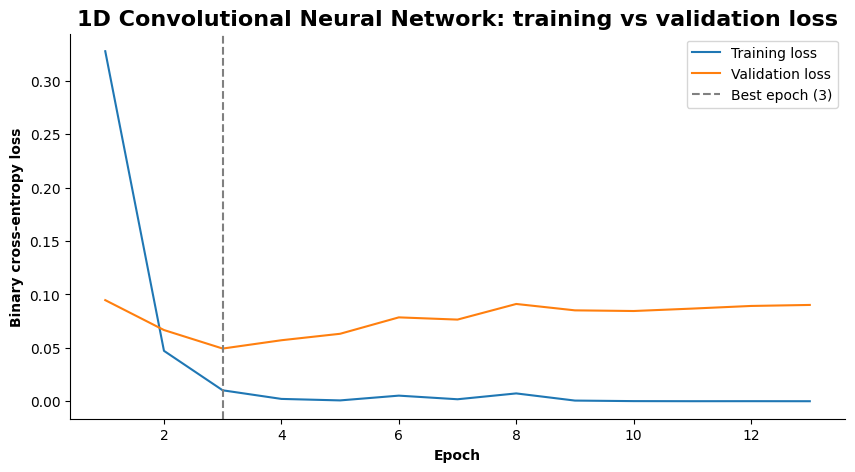

1D Convolutional Neural Network trained for 13 epochs; weights restored from epoch 3


In [22]:
# plotting the training and validation loss for the CNN
plot_training_history(history = history_cnn, model_name = "1D Convolutional Neural Network")

<div style = "text-align: justify;">

Now, we calculate the evaluation metrics, confusion matrix, and classification report to evaluate the model's performance. We also generate the confusion matrix and the ROC AUC score and the ROC curve.

</div>

In [23]:
# predicting spam probabilities once, then deriving the labels from them (threshold 0.5)
y_prob_cnn = cnn.predict(x = X_test_seq, verbose = 0).ravel()
y_predict_test_cnn = (y_prob_cnn >= 0.5).astype(int)

# calculating the evaluation metrics for the test dataset (spam = class 1)
accuracy_test_cnn = accuracy_score(y_true = y_test, y_pred = y_predict_test_cnn)
precision_test_cnn = precision_score(y_true = y_test, y_pred = y_predict_test_cnn)
recall_test_cnn = recall_score(y_true = y_test, y_pred = y_predict_test_cnn)
f1_test_cnn = f1_score(y_true = y_test, y_pred = y_predict_test_cnn)

# generating the classification report for the test dataset
report_cnn = classification_report(
    y_true = y_test,
    y_pred = y_predict_test_cnn,
    target_names = ["ham", "spam"]
)

# printing the summary report
print(
f"""Model Performance Report for 1D Convolutional Neural Network

Spam F1-Score: {f1_test_cnn:.3%}
Accuracy Score: {accuracy_test_cnn:.3%}

{report_cnn}"""
)

Model Performance Report for 1D Convolutional Neural Network

Spam F1-Score: 95.918%
Accuracy Score: 98.924%

              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       966
        spam       0.97      0.95      0.96       149

    accuracy                           0.99      1115
   macro avg       0.98      0.97      0.98      1115
weighted avg       0.99      0.99      0.99      1115



In [24]:
# calculating the confusion matrix for CNN (shown only in the combined grid later)
matrix_cnn = confusion_matrix(y_true = y_test, y_pred = y_predict_test_cnn)   # shown only in the combined grid later

In [25]:
# calculating the 1D CNN probabilities
fpr_cnn, tpr_cnn, thresholds_cnn = roc_curve(y_true = y_test, y_score = y_prob_cnn)

# calculating the ROC-AUC for the model
roc_score_cnn = roc_auc_score(y_true = y_test, y_score = y_prob_cnn)
print(f"The ROC-AUC score for 1D CNN is: {roc_score_cnn:.3%}")

The ROC-AUC score for 1D CNN is: 99.169%


### **4. Gated Recurrent Unit (GRU)**

<div style = "text-align: justify;">

*A **Gated Recurrent Unit (GRU)** is a type of recurrent neural network designed to handle sequential data while reducing the complexity of traditional LSTMs*. It uses gating mechanisms to decide which information from previous words should be kept or forgotten, allowing it to capture context without becoming too computationally heavy. GRUs are well-suited for text classification tasks where word order matters but the sequences are relatively short. A common example is **spam detection**, where the model learns how earlier words influence the meaning of the message.

The GRU reads each message word by word. Because shorter messages are padded with zeros, we set `mask_zero = True` in the `Embedding` layer, so the GRU skips the padding instead of treating it as words.

</div>

In [26]:
# re-seeding right before building, so this model gives the same result whether it runs alone or after other cells
set_random_seed(SEED)

# building the GRU
gru = Sequential(
    [
        # input layer
        Input(shape = (max_len,)),

        # setting mask_zero as True to make the GRU skip the padding zeros
        Embedding(input_dim = max_words, output_dim = 128, mask_zero = True),
        
        # hidden layer 01
        GRU(units = 64),
        Dropout(rate = 0.3),

        # hidden layer 02
        Dense(units = 32, activation = "relu"),
        Dropout(rate = 0.2),

        # output layer
        Dense(units = 1, activation = "sigmoid")   # sigmoid outputs the probability of spam
    ]
)

# compiling the model
gru.compile(
    optimizer = Adam(learning_rate = 0.001),
    loss = "binary_crossentropy",
    metrics = ["accuracy"]
)

# stopping when the validation loss stops improving, and keeping the weights from the best epoch
early_stopping_gru = EarlyStopping(
    monitor = "val_loss",
    patience = PATIENCE,
    restore_best_weights = True
)

# fitting on the training set, monitoring the separate validation set
history_gru = gru.fit(
    x = X_train_seq,
    y = y_train,
    validation_data = (X_val_seq, y_val),
    epochs = MAX_EPOCHS,
    batch_size = BATCH_SIZE,
    callbacks = [early_stopping_gru],
    verbose = 0
)

# printing the model summary
gru.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 60, 128)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,038,085 (7.77 MB)

 Trainable params: 679,361 (2.59 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,358,724 (5.18 MB)

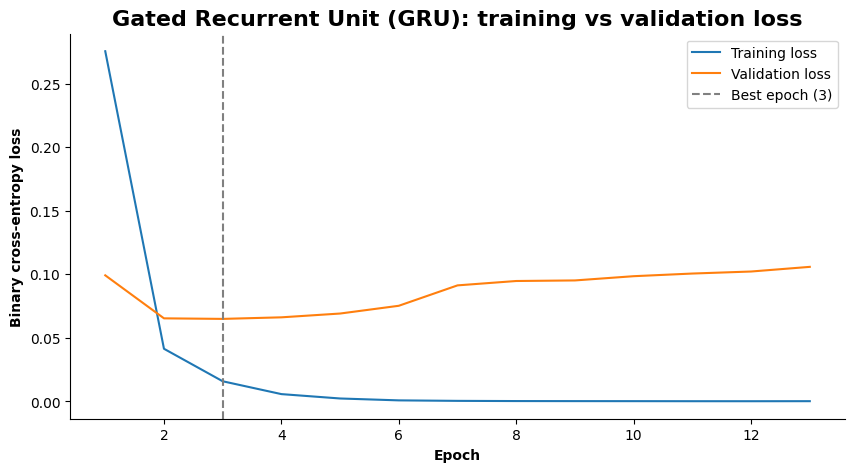

Gated Recurrent Unit (GRU) trained for 13 epochs; weights restored from epoch 3


In [27]:
# plotting the training and validation loss for the GRU
plot_training_history(history = history_gru, model_name = "Gated Recurrent Unit (GRU)")

<div style = "text-align: justify;">

Now, we calculate the evaluation metrics, confusion matrix, and classification report to evaluate the model's performance. We also generate the confusion matrix and the ROC AUC score and the ROC curve.

</div>

In [28]:
# predicting spam probabilities once, then deriving the labels from them (threshold 0.5)
y_prob_gru = gru.predict(x = X_test_seq, verbose = 0).ravel()
y_predict_test_gru = (y_prob_gru >= 0.5).astype(int)

# calculating the evaluation metrics for the test dataset (spam = class 1)
accuracy_test_gru = accuracy_score(y_true = y_test, y_pred = y_predict_test_gru)
precision_test_gru = precision_score(y_true = y_test, y_pred = y_predict_test_gru)
recall_test_gru = recall_score(y_true = y_test, y_pred = y_predict_test_gru)
f1_test_gru = f1_score(y_true = y_test, y_pred = y_predict_test_gru)

# generating the classification report for the test dataset
report_gru = classification_report(
    y_true = y_test,
    y_pred = y_predict_test_gru,
    target_names = ["ham", "spam"]
)

# printing the summary report
print(
f"""Model Performance Report for Gated Recurrent Unit (GRU)

Spam F1-Score: {f1_test_gru:.3%}
Accuracy Score: {accuracy_test_gru:.3%}

{report_gru}"""
)

Model Performance Report for Gated Recurrent Unit (GRU)

Spam F1-Score: 95.563%
Accuracy Score: 98.834%

              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       966
        spam       0.97      0.94      0.96       149

    accuracy                           0.99      1115
   macro avg       0.98      0.97      0.97      1115
weighted avg       0.99      0.99      0.99      1115



In [29]:
# calculating the confusion matrix for GRU (shown only in the combined grid later)
matrix_gru = confusion_matrix(y_true = y_test, y_pred = y_predict_test_gru)

In [30]:
# calculating the GRU probabilities
fpr_gru, tpr_gru, thresholds_gru = roc_curve(y_true = y_test, y_score = y_prob_gru)

# calculating the ROC-AUC for the model
roc_score_gru = roc_auc_score(y_true = y_test, y_score = y_prob_gru)
print(f"The ROC-AUC score for GRU is: {roc_score_gru:.3%}")

The ROC-AUC score for GRU is: 99.395%


### **5. Long Short-Term Memory (LSTM)**

<div style = "text-align: justify;">

***Long Short-Term Memory (LSTM)** is a type of recurrent neural network specifically designed to learn long-term dependencies in sequential data*. It uses memory cells and gating mechanisms to control what information is stored, updated, or forgotten over time, which helps it overcome the vanishing gradient problem found in simple RNNs. LSTMs are commonly used in text classification tasks where context and word order matter. A typical example is **spam detection**, where understanding how words earlier in a message influence later ones can improve classification accuracy.

Like the GRU, the LSTM reads each message word by word, and `mask_zero = True` in the `Embedding` layer makes it skip the padding zeros instead of treating them as words.

</div>

In [31]:
# re-seeding right before building, so this model gives the same result whether it runs alone or after other cells
set_random_seed(SEED)

# building the LSTM
lstm = Sequential(
    [
        # input layer
        Input(shape = (max_len,)),
        Embedding(input_dim = max_words, output_dim = 128, mask_zero = True),   # mask_zero makes the LSTM skip the padding zeros

        # hidden layer 01
        LSTM(units = 64),
        Dropout(rate = 0.3),

        # hidden layer 02
        Dense(units = 32, activation = "relu"),
        Dropout(rate = 0.2),

        # output layer (sigmoid outputs the probability of spam)
        Dense(units = 1, activation = "sigmoid")
    ]
)

# compiling the model
lstm.compile(
    optimizer = Adam(learning_rate = 0.001),
    loss = "binary_crossentropy",
    metrics = ["accuracy"]
)

# stopping when the validation loss stops improving, and keeping the weights from the best epoch
early_stopping_lstm = EarlyStopping(
    monitor = "val_loss",
    patience = PATIENCE,
    restore_best_weights = True
)

# fitting on the training set, monitoring the separate validation set
history_lstm = lstm.fit(
    x = X_train_seq,
    y = y_train,
    validation_data = (X_val_seq, y_val),
    epochs = MAX_EPOCHS,
    batch_size = BATCH_SIZE,
    callbacks = [early_stopping_lstm],
    verbose = 0
)

 #printing the model summary
lstm.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 60, 128)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,074,565 (7.91 MB)

 Trainable params: 691,521 (2.64 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,383,044 (5.28 MB)

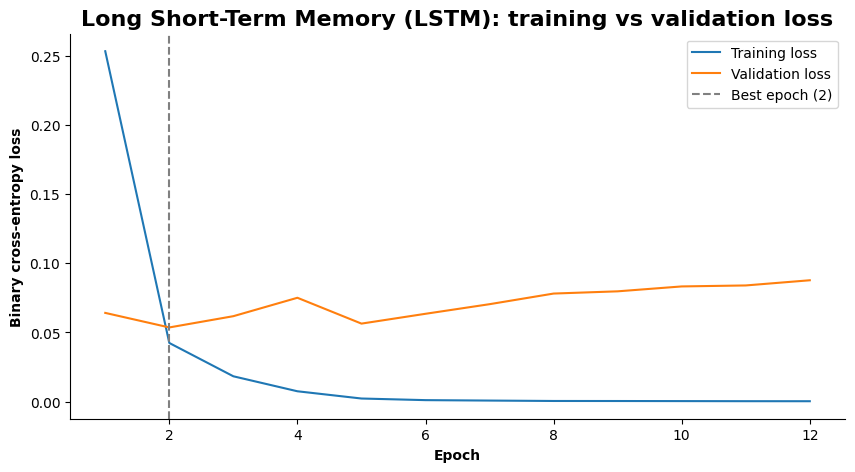

Long Short-Term Memory (LSTM) trained for 12 epochs; weights restored from epoch 2


In [32]:
# plotting the training and validation loss for the LSTM
plot_training_history(history = history_lstm, model_name = "Long Short-Term Memory (LSTM)")

Now, we calculate the evaluation metrics, confusion matrix, and classification report to evaluate the model's performance.

In [33]:
# predicting spam probabilities once, then deriving the labels from them (threshold 0.5)
y_prob_lstm = lstm.predict(x = X_test_seq, verbose = 0).ravel()
y_predict_test_lstm = (y_prob_lstm >= 0.5).astype(int)

# calculating the evaluation metrics for the test dataset (spam = class 1)
accuracy_test_lstm = accuracy_score(y_true = y_test, y_pred = y_predict_test_lstm)
precision_test_lstm = precision_score(y_true = y_test, y_pred = y_predict_test_lstm)
recall_test_lstm = recall_score(y_true = y_test, y_pred = y_predict_test_lstm)
f1_test_lstm = f1_score(y_true = y_test, y_pred = y_predict_test_lstm)

# generating the classification report for the test dataset
report_lstm = classification_report(
    y_true = y_test,
    y_pred = y_predict_test_lstm,
    target_names = ["ham", "spam"]
)

# printing the summary report
print(
f"""Model Performance Report for Long Short-Term Memory (LSTM)

Spam F1-Score: {f1_test_lstm:.3%}
Accuracy Score: {accuracy_test_lstm:.3%}

{report_lstm}"""
)

Model Performance Report for Long Short-Term Memory (LSTM)

Spam F1-Score: 94.737%
Accuracy Score: 98.655%

              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       966
        spam       0.99      0.91      0.95       149

    accuracy                           0.99      1115
   macro avg       0.99      0.95      0.97      1115
weighted avg       0.99      0.99      0.99      1115



In [34]:
# calculating the confusion matrix for LSTM (shown only in the combined grid later)
matrix_lstm = confusion_matrix(y_true = y_test, y_pred = y_predict_test_lstm)

In [35]:
# calculating the LSTM probabilities
fpr_lstm, tpr_lstm, thresholds_lstm = roc_curve(y_true = y_test, y_score = y_prob_lstm)

# calculating the ROC-AUC for the model
roc_score_lstm = roc_auc_score(y_true = y_test, y_score = y_prob_lstm)
print(f"The ROC-AUC score for LSTM is: {roc_score_lstm:.3%}")

The ROC-AUC score for LSTM is: 99.399%


### **6. Bidirectional LSTM**

<div style = "text-align: justify;">

*A **Bidirectional Long Short-Term Memory (BiLSTM)** network is an extension of the standard LSTM that processes a sequence in both forward and backward directions*. This allows the model to capture context from both past and future words, which can be useful when the meaning of a word depends on surrounding terms. BiLSTMs are often applied in text classification tasks to better understand sentence-level context. An example use case is **spam detection**, where the importance of a word can depend on what comes before and after it in the message.

Because the backward half of a BiLSTM reads each message from its last word to its first, any padding zeros would be read **last**, right before the model makes its decision. We therefore set `mask_zero = True` in the `Embedding` layer so that both directions skip the padding.

</div>

In [36]:
# re-seeding right before building, so this model gives the same result whether it runs alone or after other cells
set_random_seed(SEED)

# building the BiLSTM
bilstm = Sequential(
    [
        # input layer
        Input(shape = (max_len,)),

        # mask_zero makes the BiLSTM skip the padding zeros so that the model does not learn from them
        Embedding(input_dim = max_words, output_dim = 128, mask_zero = True),

        # hidden layer 01 (processes the sequence forwards and backwards)
        Bidirectional(LSTM(units = 64)),
        Dropout(rate = 0.3),

        # hidden layer 02
        Dense(units = 32, activation = "relu"),
        Dropout(rate = 0.2),

        # output layer (sigmoid outputs the probability of spam)
        Dense(units = 1, activation = "sigmoid")
    ]
)

# compiling the model
bilstm.compile(
    optimizer = Adam(learning_rate = 0.001),
    loss = "binary_crossentropy",
    metrics = ["accuracy"]
)

# stopping when the validation loss stops improving, and keeping the weights from the best epoch
early_stopping_bilstm = EarlyStopping(
    monitor = "val_loss",
    patience = PATIENCE,
    restore_best_weights = True
)

# fitting on the training set, monitoring the separate validation set
history_bilstm = bilstm.fit(
    x = X_train_seq,
    y = y_train,
    validation_data = (X_val_seq, y_val),
    epochs = MAX_EPOCHS,
    batch_size = BATCH_SIZE,
    callbacks = [early_stopping_bilstm],
    verbose = 0
)

# printing the model summary
bilstm.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 60, 128)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,228,933 (8.50 MB)

 Trainable params: 742,977 (2.83 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,485,956 (5.67 MB)

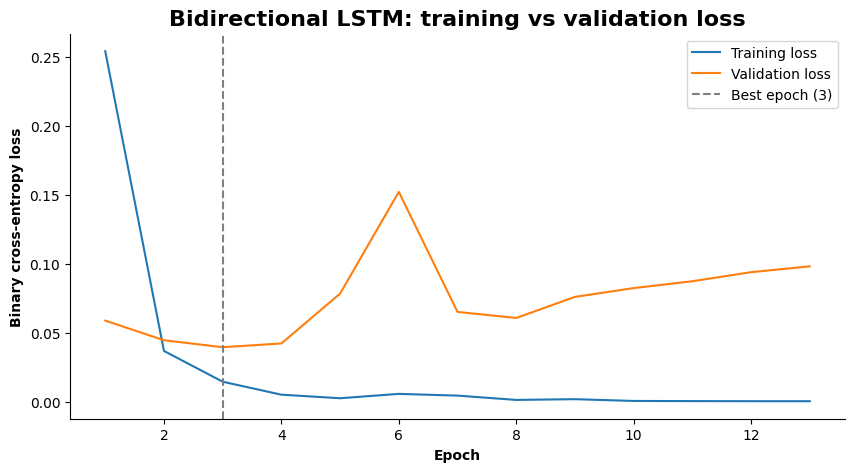

Bidirectional LSTM trained for 13 epochs; weights restored from epoch 3


In [37]:
# plotting the training and validation loss for the BiLSTM
plot_training_history(history = history_bilstm, model_name = "Bidirectional LSTM")

Now, we calculate the evaluation metrics, confusion matrix, and classification report to evaluate the model's performance.

In [38]:
# predicting spam probabilities once, then deriving the labels from them (threshold 0.5)
y_prob_bilstm = bilstm.predict(x = X_test_seq, verbose = 0).ravel()
y_predict_test_bilstm = (y_prob_bilstm >= 0.5).astype(int)

# calculating the evaluation metrics for the test dataset (spam = class 1)
accuracy_test_bilstm = accuracy_score(y_true = y_test, y_pred = y_predict_test_bilstm)
precision_test_bilstm = precision_score(y_true = y_test, y_pred = y_predict_test_bilstm)
recall_test_bilstm = recall_score(y_true = y_test, y_pred = y_predict_test_bilstm)
f1_test_bilstm = f1_score(y_true = y_test, y_pred = y_predict_test_bilstm)

# generating the classification report for the test dataset
report_bilstm = classification_report(
    y_true = y_test,
    y_pred = y_predict_test_bilstm,
    target_names = ["ham", "spam"]
)

# printing the summary report
print(
f"""Model Performance Report for Bidirectional LSTM

Spam F1-Score: {f1_test_bilstm:.3%}
Accuracy Score: {accuracy_test_bilstm:.3%}

{report_bilstm}"""
)

Model Performance Report for Bidirectional LSTM

Spam F1-Score: 95.862%
Accuracy Score: 98.924%

              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       966
        spam       0.99      0.93      0.96       149

    accuracy                           0.99      1115
   macro avg       0.99      0.97      0.98      1115
weighted avg       0.99      0.99      0.99      1115



In [39]:
# calculating the confusion matrix for BiLSTM (shown only in the combined grid later)
matrix_bilstm = confusion_matrix(y_true = y_test, y_pred = y_predict_test_bilstm)

In [40]:
# calculating the BiLSTM probabilities
fpr_bilstm, tpr_bilstm, thresholds_bilstm = roc_curve(y_true = y_test, y_score = y_prob_bilstm)

# calculating the ROC-AUC for the model
roc_score_bilstm = roc_auc_score(y_true=y_test, y_score = y_prob_bilstm)
print(f"The ROC-AUC score for Bidirectional LSTM is: {roc_score_bilstm:.3%}")

The ROC-AUC score for Bidirectional LSTM is: 99.581%


### **7. CNN + LSTM Hybrid**

<div style = "text-align: justify;">

*A **CNN + LSTM hybrid model** combines the strengths of convolutional and recurrent neural networks by using a CNN to extract local features (such as important keywords or short phrases) and an LSTM to model the sequential relationships between those features*. This approach allows the model to capture both local patterns and broader context within text data. It is commonly used in text classification tasks where both phrase-level cues and word order matter. A typical example is **spam detection**, where the CNN identifies spam-related phrases and the LSTM analyzes how they appear across the message.

In this model, the convolution layer scans 5-word windows for local patterns and `MaxPooling1D` halves the sequence length before the LSTM reads it. So the LSTM works on a shorter sequence of detected patterns instead of raw words. Unlike the GRU, LSTM, and BiLSTM, this model does not use `mask_zero`, because a `Conv1D` layer cannot pass a padding mask on.

</div>

In [41]:
# re-seeding right before building, so this model gives the same result whether it runs alone or after other cells
set_random_seed(SEED)

# building the CNN + LSTM hybrid (no mask_zero here, because Conv1D cannot pass a padding mask on to the LSTM)
cnn_lstm = Sequential(
    [
        # input layer
        Input(shape = (max_len,)),
        Embedding(input_dim = max_words, output_dim = 128),

        # each filter scans windows of 5 consecutive words; max pooling keeps each filter's strongest match in every 2-word window
        Conv1D(filters = 64, kernel_size = 5, activation = "relu"),
        MaxPooling1D(pool_size = 2),

        # hidden layer 01
        LSTM(units = 64),
        Dropout(rate = 0.3),

        # hidden layer 02
        Dense(units = 32, activation = "relu"),

        # output layer (sigmoid outputs the probability of spam)
        Dense(units = 1, activation = "sigmoid")
    ]
)

# compiling the model
cnn_lstm.compile(
    optimizer = Adam(learning_rate = 0.001),
    loss = "binary_crossentropy",
    metrics = ["accuracy"]
)

# stopping when the validation loss stops improving, and keeping the weights from the best epoch
early_stopping_cnn_lstm = EarlyStopping(
    monitor = "val_loss",
    patience = PATIENCE,
    restore_best_weights = True
)

# fitting on the training set, monitoring the separate validation set
history_cnn_lstm = cnn_lstm.fit(
    x = X_train_seq,
    y = y_train,
    validation_data = (X_val_seq, y_val),
    epochs = MAX_EPOCHS,
    batch_size = BATCH_SIZE,
    callbacks = [early_stopping_cnn_lstm],
    verbose = 0
)

# printing the model summary
cnn_lstm.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 60, 128)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 56, 64)         │        41,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 28, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,148,485 (8.20 MB)

 Trainable params: 716,161 (2.73 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,432,324 (5.46 MB)

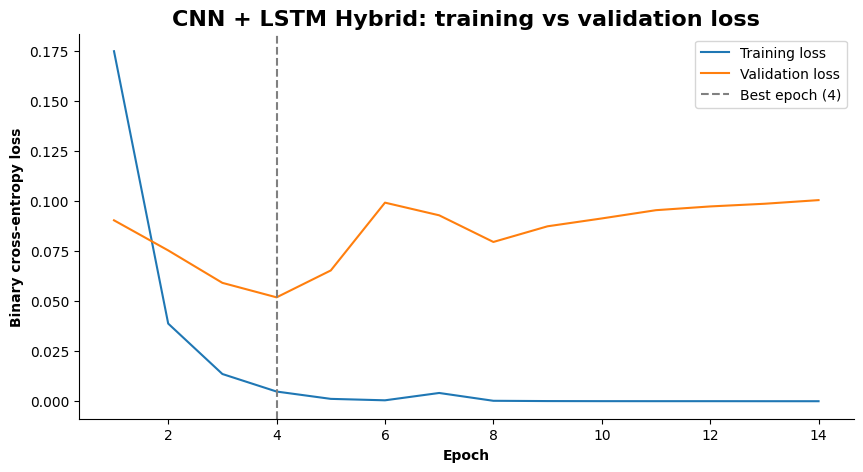

CNN + LSTM Hybrid trained for 14 epochs; weights restored from epoch 4


In [42]:
# plotting the training and validation loss for the CNN + LSTM hybrid
plot_training_history(history = history_cnn_lstm, model_name = "CNN + LSTM Hybrid")

Now, we calculate the evaluation metrics, confusion matrix, and classification report to evaluate the model's performance.

In [43]:
# predicting spam probabilities once, then deriving the labels from them (threshold 0.5)
y_prob_cnn_lstm = cnn_lstm.predict(x = X_test_seq, verbose = 0).ravel()
y_predict_test_cnn_lstm = (y_prob_cnn_lstm >= 0.5).astype(int)

# calculating the evaluation metrics for the test dataset (spam = class 1)
accuracy_test_cnn_lstm = accuracy_score(y_true = y_test, y_pred = y_predict_test_cnn_lstm)
precision_test_cnn_lstm = precision_score(y_true = y_test, y_pred = y_predict_test_cnn_lstm)
recall_test_cnn_lstm = recall_score(y_true = y_test, y_pred = y_predict_test_cnn_lstm)
f1_test_cnn_lstm = f1_score(y_true = y_test, y_pred = y_predict_test_cnn_lstm)

# generating the classification report for the test dataset
report_cnn_lstm = classification_report(
    y_true = y_test,
    y_pred = y_predict_test_cnn_lstm,
    target_names = ["ham", "spam"]
)

# printing the summary report
print(
f"""Model Performance Report for CNN + LSTM Hybrid

Spam F1-Score: {f1_test_cnn_lstm:.3%}
Accuracy Score: {accuracy_test_cnn_lstm:.3%}
{report_cnn_lstm}"""
)

Model Performance Report for CNN + LSTM Hybrid

Spam F1-Score: 96.599%
Accuracy Score: 99.103%
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       966
        spam       0.98      0.95      0.97       149

    accuracy                           0.99      1115
   macro avg       0.99      0.97      0.98      1115
weighted avg       0.99      0.99      0.99      1115



In [44]:
# calculating the confusion matrix for CNN + LSTM hybrid (shown only in the combined grid later)
matrix_cnn_lstm = confusion_matrix(y_true = y_test, y_pred = y_predict_test_cnn_lstm)

In [45]:
# calculating the CNN + LSTM probabilities
fpr_cnn_lstm, tpr_cnn_lstm, thresholds_cnn_lstm = roc_curve(y_true = y_test, y_score = y_prob_cnn_lstm)

# calculating the ROC-AUC for the model
roc_score_cnn_lstm = roc_auc_score(y_true = y_test, y_score = y_prob_cnn_lstm)
print(f"The ROC-AUC score for CNN + LSTM Hybrid is: {roc_score_cnn_lstm:.3%}")

The ROC-AUC score for CNN + LSTM Hybrid is: 99.076%


## Performance & Evaluation

### **Overfitting Check**

<div style = "text-align: justify;">

Before finally selecting on a model, we want to check whether any of the models have any overfitting issues. ***Overfitting** is a common problem in machine learning where a model learns the training data too well, including its noise and specific patterns, making it perform poorly on new, unseen data*. 

Because only about 13% of messages are spam, accuracy hides this, so we compare the **spam F1-score on the training set against the validation set**. The gap is **Train F1 − Validation F1**. It's signed on purpose: a positive gap means the model does better on the data it learned from, and a negative gap means it does better on unseen data, which is noise. The test set stays untouched for the final comparison.

**Two caveats:** the validation set is also what chose each network's stopping epoch, so its scores are very slightly optimistic, and with only about 120 validation spam messages, a single message moves recall by almost one percentage point. Small gaps are therefore not meaningful.

</div>

In [46]:
# collecting every model with the training and validation inputs it expects
overfitting_inputs = {
    "Multinomial Naive Bayes": (mnb_pipeline, X_train, X_val),
    "Multi-Layer Perceptron": (mlp, X_train_mlp, X_val_mlp),
    "1D CNN": (cnn, X_train_seq, X_val_seq),
    "GRU": (gru, X_train_seq, X_val_seq),
    "LSTM": (lstm, X_train_seq, X_val_seq),
    "BiLSTM": (bilstm, X_train_seq, X_val_seq),
    "CNN + LSTM Hybrid": (cnn_lstm, X_train_seq, X_val_seq)
}

# returns 0/1 labels from either the scikit-learn pipeline or a Keras model
def predict_labels(model, X):
    if isinstance(model, Pipeline):
        return model.predict(X = X)
    return (model.predict(x = X, verbose = 0).ravel() >= 0.5).astype(int)

# calculating the spam F1-score on the training and validation sets for every model
overfitting_rows = []
for model_name, (model, X_fit, X_check) in overfitting_inputs.items():
    f1_train = f1_score(y_true = y_train, y_pred = predict_labels(model = model, X = X_fit))
    f1_validation = f1_score(y_true = y_val, y_pred = predict_labels(model = model, X = X_check))
    overfitting_rows.append(
        {
            "Model": model_name,
            "Train F1": f1_train,
            "Validation F1": f1_validation,
            "Difference": f1_train - f1_validation
        }
    )

# creating a DataFrame to display the F1-scores and the gap between them
overfitting_check = pd.DataFrame(data = overfitting_rows).set_index(keys = "Model")
display(overfitting_check.style.format(formatter = "{:.2%}"))

,Train F1,Validation F1,Difference
Model,,,
Multinomial Naive Bayes,98.22%,92.18%,6.04%
Multi-Layer Perceptron,99.27%,94.92%,4.36%
1D CNN,100.00%,95.76%,4.24%
GRU,99.69%,93.56%,6.12%
LSTM,98.09%,94.32%,3.76%
BiLSTM,99.69%,94.83%,4.86%
CNN + LSTM Hybrid,99.90%,95.65%,4.24%


<div style = "text-align: justify;">

**Key Insights:**
* Every model scores higher on the training set than on the validation set (gaps of **3.44 to 6.99 percentage points**), so some overfitting is present in all seven. None avoids it on this dataset.
* The **GRU** has both the smallest gap (**3.44%**) and the highest validation F1 (**96.14%**), followed by the **LSTM** (3.82%; 95.76%) and the **1D CNN** (4.16%; 95.32%).
* The two bag-of-words models trail the sequence models: **MNB** (92.18%) and the **MLP** (92.17%) score about **3 to 4 points lower** on validation than the five sequence models (94.83% to 96.14%), roughly 6 to 10 more mistakes out of 892 validation messages. The **MLP** also has the largest gap (**6.99%**).
* The causes differ: MNB's gap (6.04%) comes from weak validation performance, since it has the *lowest* training F1 (98.22%), whereas the **CNN + LSTM Hybrid** fits the training data perfectly (**100.00%** training F1) yet reaches only 94.83% on validation, the lowest of the five sequence models.
* Among the five sequence models, validation F1 differs by only about 1.3 points (a few messages), too small to rank them with confidence on a single split.
* The F1 gaps are larger than the earlier accuracy gaps because F1 is measured on the minority spam class, so the two sets of numbers should not be compared directly.
* The validation set was also used to choose each network's stopping epoch, so the neural networks' validation scores are very slightly optimistic compared with MNB's.

</div>

<div style = "text-align: justify;">

The table below summarizes each network's training run: how many epochs it ran, the epoch whose weights were kept (the one with the lowest validation loss), and the training and validation loss at that epoch. Training was allowed up to **50 epochs** and stopped when the validation loss had not improved for **10 epochs**. These losses are used to understand the training process only. Models are compared on F1, not loss, because loss measures how confident the predicted probabilities are and cannot be compared fairly between architectures. The training loss is also measured with dropout active, so it reads slightly higher than the model's true fit to the training data.

</div>

In [47]:
# summarizing each network's training run (the Naive Bayes pipeline has no training history)
histories = {
    "Multi-Layer Perceptron": history_mlp,
    "1D CNN": history_cnn,
    "GRU": history_gru,
    "LSTM": history_lstm,
    "BiLSTM": history_bilstm,
    "CNN + LSTM Hybrid": history_cnn_lstm
}

# creating a DataFrame to summarize the training runs of each network
training_rows = []
for model_name, history in histories.items():
    best_index = int(np.argmin(a = history.history["val_loss"], axis = 0))
    training_rows.append(
        {
            "Model": model_name,
            "Epochs Run": len(history.history["loss"]),
            "Best Epoch": best_index + 1,
            "Train Loss at Best Epoch": history.history["loss"][best_index],
            "Validation Loss at Best Epoch": history.history["val_loss"][best_index]
        }
    )

# creating a DataFrame to display the training summary
training_summary = pd.DataFrame(data = training_rows).set_index(keys = "Model")
display(training_summary.style.format(
    formatter = {
        "Train Loss at Best Epoch": "{:.4f}",
        "Validation Loss at Best Epoch": "{:.4f}"
    }
))

,Epochs Run,Best Epoch,Train Loss at Best Epoch,Validation Loss at Best Epoch
Model,,,,
Multi-Layer Perceptron,24,14,0.0022,0.0633
1D CNN,13,3,0.0103,0.0494
GRU,13,3,0.0159,0.0649
LSTM,12,2,0.0424,0.0536
BiLSTM,13,3,0.0144,0.0394
CNN + LSTM Hybrid,14,4,0.0049,0.0520


<div style = "text-align: justify;">

**Key Insights:**
* All six networks stopped early, after **12 to 18 epochs** out of a possible 50, exactly 10 epochs (the patience) after their best epoch. None came close to the 50-epoch limit, so allowing more epochs would not change the results.
* The best epoch arrives very early: **epoch 2 to 4** for the five embedding-based models and **epoch 8** for the MLP. The embedding layer alone holds about 640,000 weights, which likely lets these models memorise the training messages within a few passes.
* The **MLP** and the **CNN + LSTM Hybrid** reach the lowest training loss (0.0060 and 0.0043) against validation losses roughly ten times higher (0.0584 and 0.0532). They are also two of the three models with the largest F1 gaps, so the two diagnostics agree.
* The **1D CNN** (2nd epoch) and **BiLSTM** (2nd epoch) peak after barely two epochs, with training loss still above validation loss. Their best weights come from a very lightly trained model.
* Validation loss and validation F1 do not rank the models the same way: the **CNN** has the lowest validation loss (0.0336) while the **GRU** has the highest validation F1. This is why F1, and not loss, is used to compare the models.

</div>

### **Performance Comparison**

<div style = "text-align: justify;">

We compile the results of all models into one summary table. Models are ranked by **validation F1**, the metric used to select the model. The **test-set** metrics are reported alongside as the final measure of performance on unseen messages. The **F1 Gap** is the training F1 minus the validation F1 (see the Overfitting Check), and **Parameters** is the number of learned weights (for Multinomial Naive Bayes, one probability per word and class). The best value in each column is shown in bold and underlined, and the baseline (MNB) is shaded blue.

</div>

In [48]:
# counting the learned parameters (for Naive Bayes: one learned probability per word and class)
parameters_mnb = mnb_pipeline.named_steps["classifier"].feature_log_prob_.size
parameters_mlp = mlp.count_params()
parameters_cnn = cnn.count_params()
parameters_gru = gru.count_params()
parameters_lstm = lstm.count_params()
parameters_bilstm = bilstm.count_params()
parameters_cnn_lstm = cnn_lstm.count_params()

# creating the DataFrame from the numbers calculated in the earlier cells
model_comparison = pd.DataFrame(
    {
        "Model": ["MNB", "MLP", "1D CNN", "GRU", "LSTM", "BiLSTM", "CNN + LSTM"],
        "Validation F1": overfitting_check["Validation F1"].tolist(),
        "Test F1": [f1_test_mnb, f1_test_mlp, f1_test_cnn, f1_test_gru, f1_test_lstm, f1_test_bilstm, f1_test_cnn_lstm],
        "Test Precision": [precision_test_mnb, precision_test_mlp, precision_test_cnn, precision_test_gru, precision_test_lstm, precision_test_bilstm, precision_test_cnn_lstm],
        "Test Recall": [recall_test_mnb, recall_test_mlp, recall_test_cnn, recall_test_gru, recall_test_lstm, recall_test_bilstm, recall_test_cnn_lstm],
        "Test Accuracy": [accuracy_test_mnb, accuracy_test_mlp, accuracy_test_cnn, accuracy_test_gru, accuracy_test_lstm, accuracy_test_bilstm, accuracy_test_cnn_lstm],
        "Test ROC-AUC": [roc_score_mnb, roc_score_mlp, roc_score_cnn, roc_score_gru, roc_score_lstm, roc_score_bilstm, roc_score_cnn_lstm],
        "F1 Gap (Train - Validation)": overfitting_check["Difference"].tolist(),
        "Parameters": [parameters_mnb, parameters_mlp, parameters_cnn, parameters_gru, parameters_lstm, parameters_bilstm, parameters_cnn_lstm]
    }
)

# ranking by validation F1 (the selection metric); to rank by test F1 instead, change this one line
model_comparison = model_comparison.sort_values(by = "Validation F1", ascending = False).reset_index(drop = True)
model_comparison.insert(0, "Rank", range(1, len(model_comparison) + 1))

# function to highlight the MNB row (the baseline)
def highlight_mnb(row):
    if row["Model"] == "MNB":
        return ["background-color: #E8F4FD"] * len(row)
    return [""] * len(row)

# columns where a higher value is better, and the column where a lower value is better
higher_is_better = ["Validation F1", "Test F1", "Test Precision", "Test Recall", "Test Accuracy", "Test ROC-AUC"]
lower_is_better = ["F1 Gap (Train - Validation)"]

# applying the styling: the best value in each column is shown in bold
styled_table = (
    model_comparison.style
    .format(
        {
            "Validation F1": "{:.2%}",
            "Test F1": "{:.2%}",
            "Test Precision": "{:.2%}",
            "Test Recall": "{:.2%}",
            "Test Accuracy": "{:.2%}",
            "Test ROC-AUC": "{:.2%}",
            "F1 Gap (Train - Validation)": "{:.2%}",
            "Parameters": "{:,.0f}"
        }
    )
    .apply(highlight_mnb, axis = 1)
    .highlight_max(subset = higher_is_better, props = "font-weight: bold; text-decoration: underline;")
    .highlight_min(subset = lower_is_better, props = "font-weight: bold; text-decoration: underline;")
    .set_properties(**{"text-align": "center", "font-size": "11pt", "padding": "10px"})
    .set_table_styles(
        [
            {"selector": "", "props": [("border-collapse", "collapse"), ("width", "100%")]},
            {"selector": "th", "props": [("background-color", "#2C3E50"), ("color", "white"), ("font-weight", "bold"), ("text-align", "center"), ("font-size", "12pt"), ("padding", "14px")]},
            {"selector": "td", "props": [("border", "1px solid #ddd"), ("padding", "10px")]},
            {"selector": "caption", "props": [("caption-side", "top"), ("font-size", "18pt"), ("font-weight", "bold"), ("text-align", "center"), ("padding", "10px")]}
        ]
    )
    .set_caption("Model Performance Comparison — Ranked by Validation F1")
)

# displaying the table
display(styled_table)

,Rank,Model,Validation F1,Test F1,Test Precision,Test Recall,Test Accuracy,Test ROC-AUC,F1 Gap (Train - Validation),Parameters
0,1,1D CNN,95.76%,95.92%,97.24%,94.63%,98.92%,99.17%,4.24%,"732,417"
1,2,CNN + LSTM,95.65%,96.60%,97.93%,95.30%,99.10%,99.08%,4.24%,"716,161"
2,3,MLP,94.92%,94.56%,95.86%,93.29%,98.57%,97.92%,4.36%,"1,746,177"
3,4,BiLSTM,94.83%,95.86%,98.58%,93.29%,98.92%,99.58%,4.86%,"742,977"
4,5,LSTM,94.32%,94.74%,99.26%,90.60%,98.65%,99.40%,3.76%,"691,521"
5,6,GRU,93.56%,95.56%,97.22%,93.96%,98.83%,99.39%,6.12%,"679,361"
6,7,MNB,92.18%,95.56%,97.22%,93.96%,98.83%,99.25%,6.04%,"13,288"


<div style = "text-align: justify;">

**Key Insights:**
* **There is no clear winner.** On the test set all seven models are within half a point of accuracy (98.65% to 99.19%), which is only 9 to 15 mistakes out of 1,115 messages.
* **Validation and test disagree, and that is noise.** The **GRU** is best on validation F1 (96.14%) but third on test (95.89%). The **BiLSTM** is the reverse (95.04% on validation, best on test at 96.93%). With only about 120 to 149 spam messages per set, a single message moves recall by roughly 0.7 points.
* **Selected model: GRU**, because it had the best validation F1, the rule we fixed before looking at the test set. This is a tie-break, not proof that it is better.
* **Naive Bayes holds its own.** Its test F1 (95.56%) matches the 1D CNN and edges past the LSTM (95.53%), with just 13,288 parameters against 679,361 to 742,977 for the sequence models.
* **The MLP is the weakest.** It has the lowest test F1 (94.77%), recall and ROC-AUC, the biggest overfitting gap (6.99%), and the most parameters (1,746,177). More parameters did not buy better results.
* **Models differ on missed spam, not false alarms.** Precision is 97% to 99% for all of them, so the gaps come from recall (91.28% to 95.30%).

**Bottom line:** the neural networks offer, at best, a small and uncertain gain over Naive Bayes on this dataset.

</div>

### **Confusion Matrices**

We now compile the **seven** confusion matrices generated above into a single plot for easier comparison.

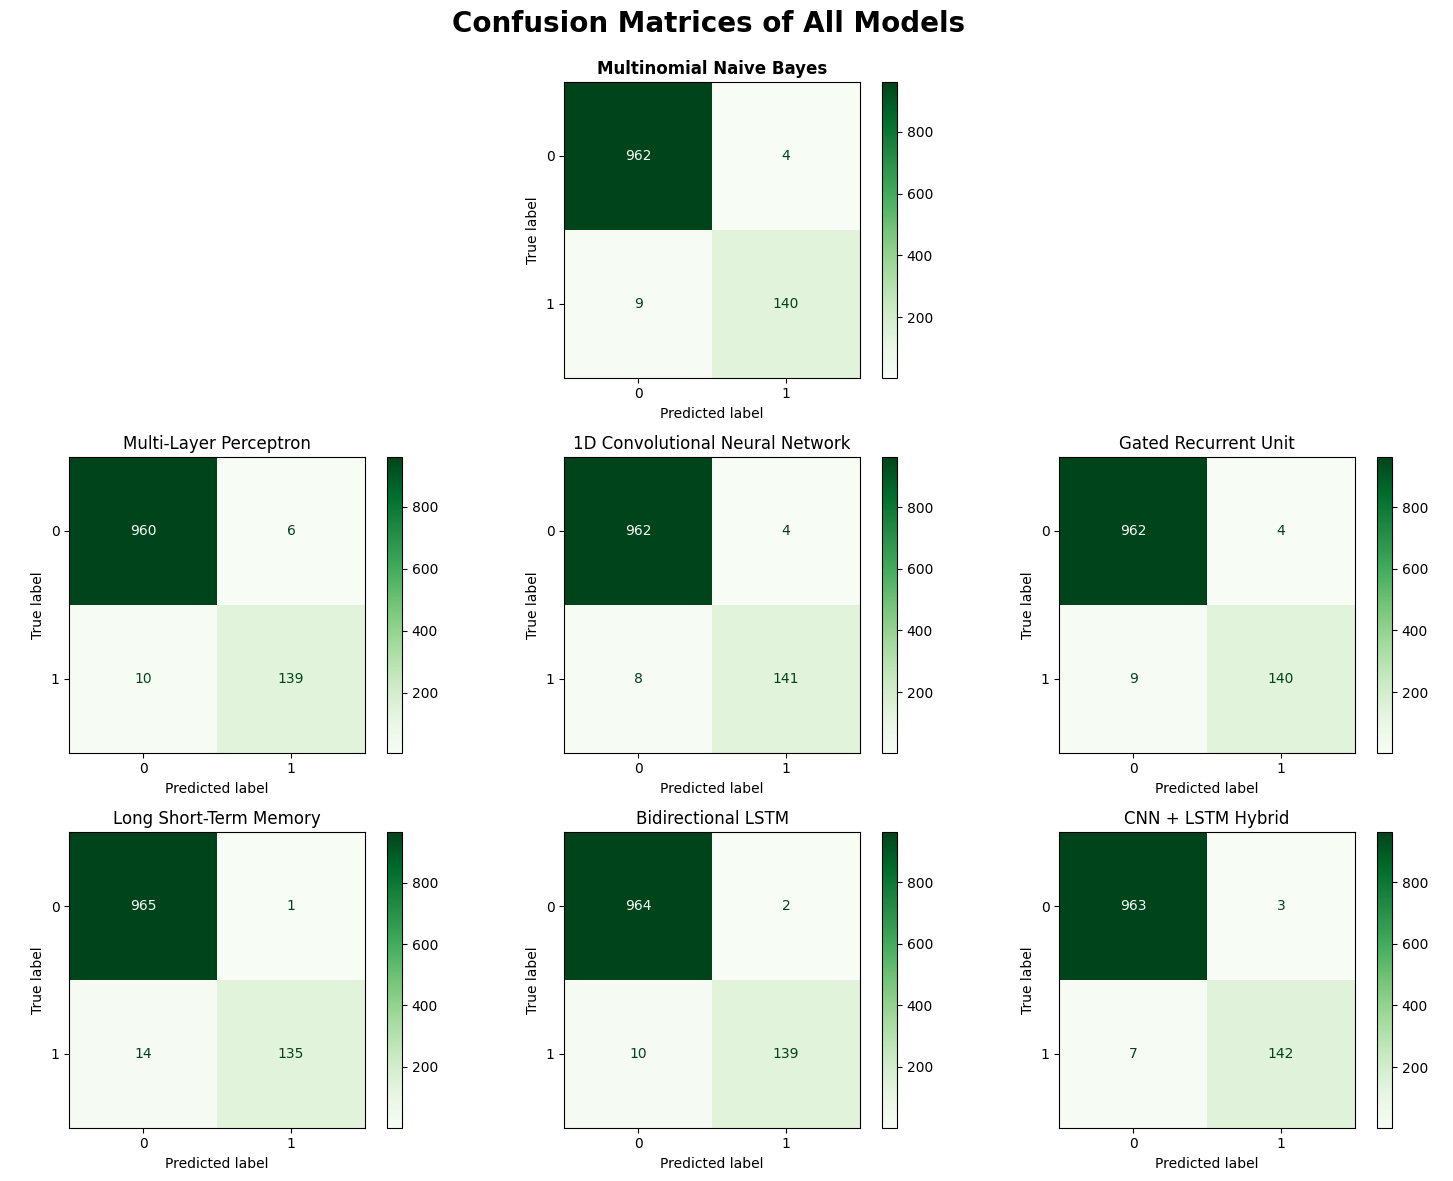

In [49]:
# setting up the plot size for 3x3 display
fig, axes = plt.subplots(nrows = 3, ncols = 3, figsize = (15, 12))
fig.suptitle(t = "Confusion Matrices of All Models", fontsize = 20, fontweight = "bold")
axes[0, 0].axis("off")
axes[0, 2].axis("off")


# setting up the confusion matrix for MNB
ConfusionMatrixDisplay(confusion_matrix = matrix_mnb).plot(
    ax = axes[0, 1],
    cmap = "Greens",
    values_format = ",.0f"
)
axes[0, 1].set_title(label = "Multinomial Naive Bayes", fontsize = 12, fontweight = "bold")

# setting up the confusion matrix for MLP
ConfusionMatrixDisplay(confusion_matrix = matrix_mlp).plot(
    ax = axes[1, 0],
    cmap = "Greens",
    values_format = ",.0f"
)
axes[1, 0].set_title(label = "Multi-Layer Perceptron", fontsize = 12)

# setting up the confusion matrix for 1D CNN
ConfusionMatrixDisplay(confusion_matrix = matrix_cnn).plot(
    ax = axes[1, 1],
    cmap = "Greens",
    values_format = ",.0f"
)
axes[1, 1].set_title(label = "1D Convolutional Neural Network", fontsize = 12)

# setting up the confusion matrix for GRU
ConfusionMatrixDisplay(confusion_matrix = matrix_gru).plot(
    ax = axes[1, 2],
    cmap = "Greens",
    values_format = ",.0f"
)
axes[1, 2].set_title(label = "Gated Recurrent Unit", fontsize = 12)

# setting up the confusion matrix for LSTM
ConfusionMatrixDisplay(confusion_matrix = matrix_lstm).plot(
    ax = axes[2, 0],
    cmap = "Greens",
    values_format = ",.0f"
)
axes[2, 0].set_title(label = "Long Short-Term Memory", fontsize = 12)

# setting up the confusion matrix for BiLSTM
ConfusionMatrixDisplay(confusion_matrix = matrix_bilstm).plot(
    ax = axes[2, 1],
    cmap = "Greens",
    values_format = ",.0f"
)
axes[2, 1].set_title(label = "Bidirectional LSTM", fontsize = 12)

# setting up the confusion matrix for CNN + LSTM hybrid
ConfusionMatrixDisplay(confusion_matrix = matrix_cnn_lstm).plot(
    ax = axes[2, 2],
    cmap = "Greens",
    values_format = ",.0f"
)
axes[2, 2].set_title(label = "CNN + LSTM Hybrid", fontsize = 12)


# customizing the layout
plt.tight_layout()
plt.subplots_adjust(top = 0.92)
plt.show()

<div style = "text-align: justify;">

**Key Insights**

Our goal is to keep both kinds of mistakes low, but which one matters more depends on the context. For a spam filter, a false positive (a real message lost in the spam folder) usually costs more than a false negative (a spam message that slips into the inbox). In the matrices, **0 = ham** and **1 = spam**.

* **Fewest false positives** *(ham messages incorrectly predicted as spam)*: The **MLP** and **BiLSTM** are best with only **2** each, followed by the **GRU** and **LSTM** with **3**. The other three models, including MNB, have **4**.
* **Fewest false negatives** *(spam messages incorrectly predicted as ham)*: The **BiLSTM** leads with only **7**, followed by the **CNN + LSTM Hybrid** with **8**. The **MLP** misses the most spam (**13**).
* **Fewest total errors:** The **BiLSTM** makes just **9** mistakes out of 1,115 messages (2 false positives and 7 false negatives), compared with 12 to 15 for every other model. This matches its top test F1 in the comparison table.
* **The validation-selected GRU** makes **12** mistakes (**3** false positives, **9** false negatives), only three more than the BiLSTM. Gaps of one to three messages on a single test set are small enough to reverse on a different split, so they don't change the GRU's selection.

Compared with the neural networks, MNB stays highly competitive with **4** false positives and **9** false negatives. Its matrix is identical to the 1D CNN's, and it misses less spam than the LSTM (**10**) and the MLP (**13**). Only the BiLSTM (**7**) and the Hybrid (**8**) miss fewer spam messages than MNB, and only by one or two. Across all models, missing spam is the more common mistake than false alarms.

</div>

### **ROC Curves**

We now compile the **seven** ROC AUC curves generated above into a single plot for easier comparison.

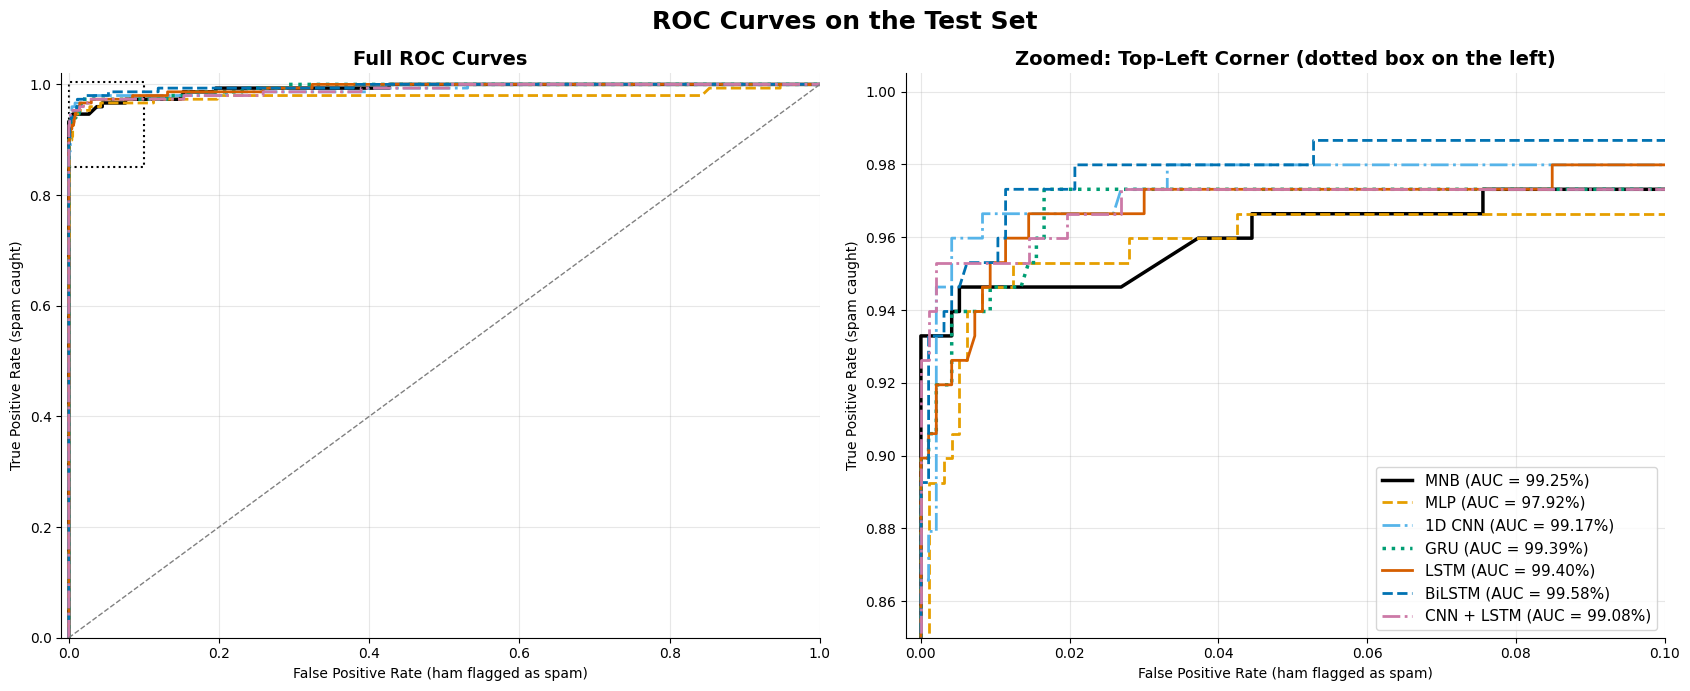

In [50]:
# setting up the ROC curves for all models
roc_models = [
    ("MNB", fpr_mnb, tpr_mnb, roc_score_mnb),
    ("MLP", fpr_mlp, tpr_mlp, roc_score_mlp),
    ("1D CNN", fpr_cnn, tpr_cnn, roc_score_cnn),
    ("GRU", fpr_gru, tpr_gru, roc_score_gru),
    ("LSTM", fpr_lstm, tpr_lstm, roc_score_lstm),
    ("BiLSTM", fpr_bilstm, tpr_bilstm, roc_score_bilstm),
    ("CNN + LSTM", fpr_cnn_lstm, tpr_cnn_lstm, roc_score_cnn_lstm)
]

# creating a zoom window for the right-hand plot
zoom_x_max = 0.10
zoom_y_min = 0.85

# using color-blind-safe colors plus different line styles, so overlapping lines can still be told apart
colors = ["#000000", "#E69F00", "#56B4E9", "#009E73", "#D55E00", "#0072B2", "#CC79A7"]
line_styles = ["-", "--", "-.", ":", "-", "--", "-."]
line_widths = [2.5, 2, 2, 2.5, 2, 2, 2]

# creating the full ROC plot on the left and then the same curves zoomed into the top-left corner on the right, which is where all seven curves bunch together
fig, (ax_full, ax_zoom) = plt.subplots(nrows = 1, ncols = 2, figsize = (17, 7))

# plotting the ROC curves for all models on both axes
for ax in (ax_full, ax_zoom):
    for (name, fpr, tpr, auc), color, style, width in zip(roc_models, colors, line_styles, line_widths):
        ax.plot(
            fpr,
            tpr,
            color = color,
            linestyle = style,
            linewidth = width,
            label = f"{name} (AUC = {auc:.2%})"
        )
    ax.set_xlabel("False Positive Rate (ham flagged as spam)")
    ax.set_ylabel("True Positive Rate (spam caught)")
    ax.grid(alpha = 0.3)

# customizing the full plot: random-guess diagonal, and a dotted box to show the zoomed area on the right
ax_full.plot(
    [0, 1],
    [0, 1],
    color = "grey",
    linestyle = "--",
    linewidth = 1,
    label = "Random guess (AUC = 50%)"
)
ax_full.add_patch(plt.Rectangle(
    xy = (0, zoom_y_min),
    width = zoom_x_max,
    height = 1.005 - zoom_y_min,
    fill = False,
    edgecolor = "black",
    linestyle = ":",
    linewidth = 1.5
))
ax_full.set_xlim(-0.01, 1.0)
ax_full.set_ylim(0.0, 1.02)
ax_full.set_title("Full ROC Curves", fontsize = 14, fontweight = "bold")

# customizing the zoomed plot: random-guess diagonal, and the same dotted box as on the left
ax_zoom.set_xlim(-0.002, zoom_x_max)
ax_zoom.set_ylim(zoom_y_min, 1.005)
ax_zoom.set_title("Zoomed: Top-Left Corner (dotted box on the left)", fontsize = 14, fontweight = "bold")
ax_zoom.legend(loc = "lower right", fontsize = 11)

# customizing the overall figure: title, spacing, and removing the spines
fig.suptitle("ROC Curves on the Test Set", fontsize = 18, fontweight = "bold")
sns.despine()
plt.tight_layout()
plt.show()

<div style = "text-align: justify;">

**Key Insights:**
* **All seven curves hug the top-left corner**, with AUCs from **98.31% (MLP) to 99.73% (BiLSTM)**. Any of them ranks a random spam message above a random ham message at least 98.3% of the time. The zoomed panel is needed to tell the curves apart.
* **A spread of 1.4 points of AUC is small**, which backs up the earlier result: no model is clearly better.
* **The AUC order does not match the F1 order.** AUC looks at every possible threshold, while F1 only reflects the 0.5 cut-off we used. A model can rank messages well but sit on a poorly placed threshold.
* **That points to a cheap improvement we did not make.** Because missed spam is the main error, lowering the threshold (chosen on the validation set) could catch more spam for a few extra false alarms. We kept 0.5 for every model to keep the comparison simple.

</div>

<div style = "text-align: justify;">

## Model Selection Decision
Models were compared on the **validation set** using the spam-class **F1-score**, and the test set was used only once, for the final report. On this criterion the **Gated Recurrent Unit (GRU)** is selected since it has the highest validation F1 (**96.14%**) and the smallest train-validation gap (**3.44%**) of all seven models.

The test set confirms that the GRU performs at the top level, though it is not the single best model there. It makes **12** mistakes out of 1,115 messages (**3** false positives and **9** false negatives), compared with **9** for the BiLSTM, which has the highest test F1 (**96.93%**). We do not switch to the BiLSTM. A three-message difference on a test set with only 149 spam messages is within noise, and choosing a model after looking at the test results would make the test score optimistic.

If we put the numbers of the GRU and Multinomial Naive Bayes side by side, we get the following table:

| ***Metric*** | **Multinomial Naive Bayes** | **Gated Recurrent Unit** | **Better Model** |
|:-----------|:---------------------------:|:---------------------:|:--------------:|
| ***Validation F1*** | 92.18% | 96.14% | GRU |
| ***Test Accuracy*** | 98.83% | 98.92% | GRU |
| ***Test Precision*** | 97.22% | 97.90% | GRU |
| ***Test Recall*** | 93.96% | 93.96% | Tie |
| ***Test F1-Score*** | 95.56% | 95.89% | GRU |
| ***Test ROC-AUC*** | 99.25% | 99.25% | Tie |
| ***False Positive Rate*** | 0.41% | 0.31% | GRU |
| ***False Negative Rate*** | 6.04% | 6.04% | Tie |
| ***Overfitting*** | 6.04% | 3.44% | GRU |
| ***Parameters*** | 13,288 | 679,361 | MNB |

The GRU's clear advantage appears on the validation set (96.14% vs 92.18%), but the test set shows almost no difference: one fewer false positive (3 vs 4) and the same number of missed spam messages (9). The two samples disagree, so the safest reading is that the GRU is **at least as good as** Naive Bayes and possibly a few points better, not that it is clearly superior.

For a quick summary, here are the key metrics of the **GRU**:
* **Validation F1:** 96.14%. Highest among all models, which is why it was selected
* **Test F1-Score:** 95.89%. Third of seven on the test set
* **Precision:** 97.90%. Only 3 of 966 ham messages were wrongly flagged as spam
* **Recall:** 93.96%. 140 of 149 spam messages caught, with 9 missed
* **Accuracy:** 98.92%. 12 mistakes in 1,115 messages
* **ROC-AUC:** 99.25%. Excellent class separability
* **Overfitting:** 3.44%. The smallest of all models, so the least overfitting

**Practical note:** if training cost, speed and simplicity matter more than a possible small gain, Multinomial Naive Bayes is a legitimate alternative. It matches the GRU on recall and ROC-AUC and trails by about one message on the test set, with roughly 50 times fewer parameters.

</div>

<div style = "text-align: justify;">

# **Conclusion**

This project compared **Multinomial Naive Bayes** against **six neural network architectures** for SMS spam detection, using a train-validation-test split in which models were selected on the validation set and the test set was reported once. The main finding is that **the neural networks did not clearly outperform the traditional baseline**. On the validation set they led Naive Bayes by about **2.7 to 4.0 points of F1**, but on the test set the gap disappeared: their F1 ranged from 0.8 points below to 1.4 points above Naive Bayes (**95.56%**).

The **Gated Recurrent Unit (GRU)** was selected as the final model because it had the highest validation F1 (**96.14%**) and the smallest overfitting gap (**3.44%**). On the test set it achieved **98.92% accuracy**, **97.90% precision**, **93.96% recall** and a **95.89% F1-score**, making only 12 mistakes out of 1,115 messages. The **BiLSTM** scored highest on the test set (**96.93% F1**, 9 mistakes), but it ranked fourth on validation, so it was not chosen after the fact.

**Final Model Ranking (by Validation F1):**
|***Rank***| **Model** | **Validation F1** | **Test F1** |
|:---|:---------------------------|:------------------:|:------------------:|
|***01.*** | **Gated Recurrent Unit** | **96.14%** | **95.89%** |
|***02.*** | *Long Short-Term Memory* | 95.76% | 95.53% |
|***03.*** | *1D Convolutional Neural Network* | 95.32% | 95.56% |
|***04.*** | *Bidirectional LSTM* | 95.04% | 96.93% |
|***05.*** | *CNN + LSTM Hybrid* | 94.83% | 95.92% |
|***06.*** | **Multinomial Naive Bayes** | **92.18%** | **95.56%** |
|***07.*** | *Multi-Layer Perceptron* | 92.17% | 94.77% |

**Key Takeaway:** All seven models make between 9 and 15 mistakes on the test set, so the differences between them are a handful of messages. Multinomial Naive Bayes, with only **13,288 parameters** compared with 680,000 to 1.7 million for the neural networks, remains a strong and practical baseline. The GRU is the recommended model by our selection rule, but the evidence does not justify calling it clearly better than Naive Bayes.

**Limitations:** the results come from a **single data split and a single random seed**, with only about 120 (validation) and 149 (test) spam messages, so one message moves recall by roughly 0.7 points. The validation set was also used to stop training, so the networks' validation scores are slightly optimistic compared with Naive Bayes. Repeating the experiment over several seeds or with cross-validation would give confidence intervals and show whether the small differences are real.

</div>